# Simülasyon Çalışması: ANOVA mı, Welch mi, Kruskal-Wallis mi?

`02_gercek_veri.ipynb` dosyasında normallik sağlanmadığı için Kruskal-Wallis testi seçildi. Ancak ANOVA'nın büyük örneklemde normallik ihlaline dayanıklı olduğu sık söylenir. **Bu seçim gerçekten gerekli miydi? Hangi koşulda hangi test daha güvenilir?**

Bu soruyu Monte Carlo simülasyonuyla yanıtlıyoruz. Her koşulda binlerce veri seti üretilir, üç test uygulanır ve iki ölçüt hesaplanır:

- **I. tip hata oranı:** Gruplar arasında gerçekte fark yokken testin "fark var" deme oranı. İdeal değer α = 0.05'tir. Bradley (1978) ölçütüne göre 0.025–0.075 aralığı **kabul edilebilir** sayılır.
- **Güç (power):** Gerçekte fark varken testin bu farkı yakalama oranı. Yüksek olması iyidir.

**Koşullar**

| Faktör | Düzeyler |
|---|---|
| Dağılım | Normal, Çarpık (log-normal), Ağır kuyruklu (t, sd = 3), **Gerçek not dağılımı** (Portekizce G3'ten bootstrap) |
| Grup büyüklükleri | Dengeli (30, 30, 30, 30); Dengesiz, gerçek verideki oranlar (39, 56, 18, 7) |
| Standart sapmalar | Eşit; küçük grupta 2 kat; büyük grupta 2 kat |

Tüm dağılımlar ortalama 0 ve standart sapma 1 olacak şekilde standartlaştırılır; böylece yalnızca **dağılım şekli** değişir.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, str(Path("..") / "src"))
import istatistik as ist

SEKIL = Path("..") / "figures"
TEKRAR = 5000          # her koşul için simülasyon sayısı
ALPHA = 0.05
rng = np.random.default_rng(2024)

TESTLER = {
    "ANOVA":          lambda g: stats.f_oneway(*g, axis=1).pvalue,
    "Welch ANOVA":    lambda g: stats.f_oneway(*g, axis=1, equal_var=False).pvalue,
    "Kruskal-Wallis": lambda g: stats.kruskal(*g, axis=1).pvalue,
}
TEST_RENK = {"ANOVA": "#d95f02", "Welch ANOVA": "#7570b3", "Kruskal-Wallis": "#1b9e77"}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Dağılımlar

Gerçek not dağılımı için Portekizce dersinde final sınavına giren öğrencilerin (G3 > 0) notları havuzlanır ve standartlaştırılır. Simülasyonda bu havuzdan iadeli örnekleme yapılır.

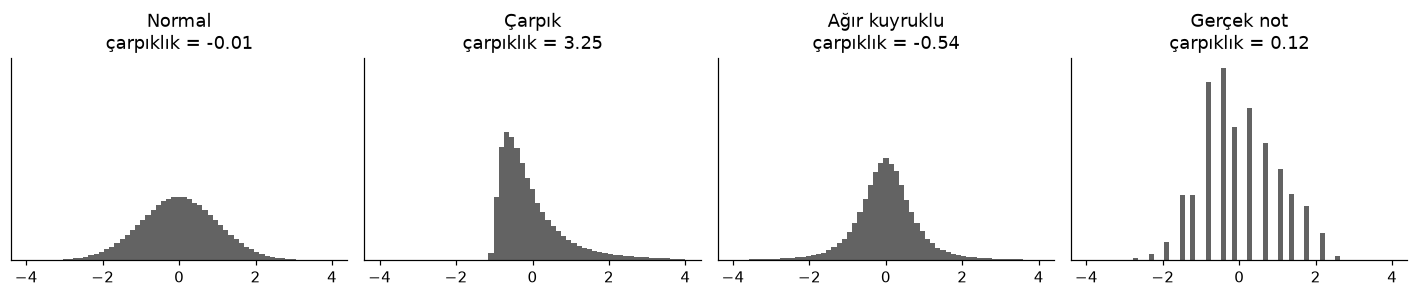

In [2]:
por = pd.read_csv(Path("..") / "data" / "student-por.csv", sep=";")
por_g = por[por.G3 > 0]
gercek_havuz = ((por_g.G3 - por_g.G3.mean()) / por_g.G3.std()).to_numpy()

LOG_SIGMA = 0.75
lognormal_ort = np.exp(LOG_SIGMA ** 2 / 2)
lognormal_ss = np.sqrt((np.exp(LOG_SIGMA ** 2) - 1) * np.exp(LOG_SIGMA ** 2))

DAGILIMLAR = {
    "Normal":          lambda boyut: rng.standard_normal(boyut),
    "Çarpık":          lambda boyut: (rng.lognormal(0, LOG_SIGMA, boyut) - lognormal_ort) / lognormal_ss,
    "Ağır kuyruklu":   lambda boyut: rng.standard_t(3, boyut) / np.sqrt(3),
    "Gerçek not":      lambda boyut: rng.choice(gercek_havuz, boyut),
}

fig, eksenler = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for eksen, (ad, uret) in zip(eksenler, DAGILIMLAR.items()):
    ornek = uret(200_000)
    eksen.hist(ornek, bins=np.linspace(-4, 4, 60), density=True, color="#636363")
    eksen.set_title(f"{ad}\nçarpıklık = {stats.skew(ornek):.2f}")
    eksen.set_yticks([])
plt.tight_layout()
plt.show()

## 2. Simülasyon fonksiyonu

Her tekrar için grup verileri `(TEKRAR, n_j)` boyutlu matrisler olarak tek seferde üretilir; testler `axis=1` ile vektörize çalışır. Böylece 5000 tekrar saniyeler içinde biter.

In [3]:
def simule_et(dagilim, n_ler, ss_ler, kaymalar, tekrar=TEKRAR):
    # Her test için H0'ı reddetme oranını döndürür
    gruplar = [DAGILIMLAR[dagilim]((tekrar, n)) * s + m for n, s, m in zip(n_ler, ss_ler, kaymalar)]
    return {ad: float((test(gruplar) < ALPHA).mean()) for ad, test in TESTLER.items()}


TASARIMLAR = {"Dengeli": (30, 30, 30, 30), "Dengesiz": (39, 56, 18, 7)}
VARYANSLAR = {"Eşit SS": (1, 1, 1, 1),
              "Küçük grupta 2× SS": (1, 1, 1, 2),
              "Büyük grupta 2× SS": (1, 2, 1, 1)}

## 3. I. tip hata oranları (H₀ doğru)

In [4]:
satirlar = []
for dagilim in DAGILIMLAR:
    for tasarim, n_ler in TASARIMLAR.items():
        for varyans, ss_ler in VARYANSLAR.items():
            oranlar = simule_et(dagilim, n_ler, ss_ler, (0, 0, 0, 0))
            satirlar.append({"Dağılım": dagilim, "Tasarım": tasarim, "Varyans": varyans, **oranlar})

tip1 = pd.DataFrame(satirlar)
tip1.round(3)

,Dağılım,Tasarım,Varyans,ANOVA,Welch ANOVA,Kruskal-Wallis
0,Normal,Dengeli,Eşit SS,0.052,0.053,0.050
1,Normal,Dengeli,Küçük grupta 2× SS,0.068,0.052,0.060
2,Normal,Dengeli,Büyük grupta 2× SS,0.065,0.047,0.053
3,Normal,Dengesiz,Eşit SS,0.053,0.061,0.052
4,Normal,Dengesiz,Küçük grupta 2× SS,0.187,0.054,0.093
5,Normal,Dengesiz,Büyük grupta 2× SS,0.014,0.054,0.023
6,Çarpık,Dengeli,Eşit SS,0.042,0.053,0.045
7,Çarpık,Dengeli,Küçük grupta 2× SS,0.071,0.069,0.246
8,Çarpık,Dengeli,Büyük grupta 2× SS,0.070,0.066,0.254
9,Çarpık,Dengesiz,Eşit SS,0.054,0.103,0.052


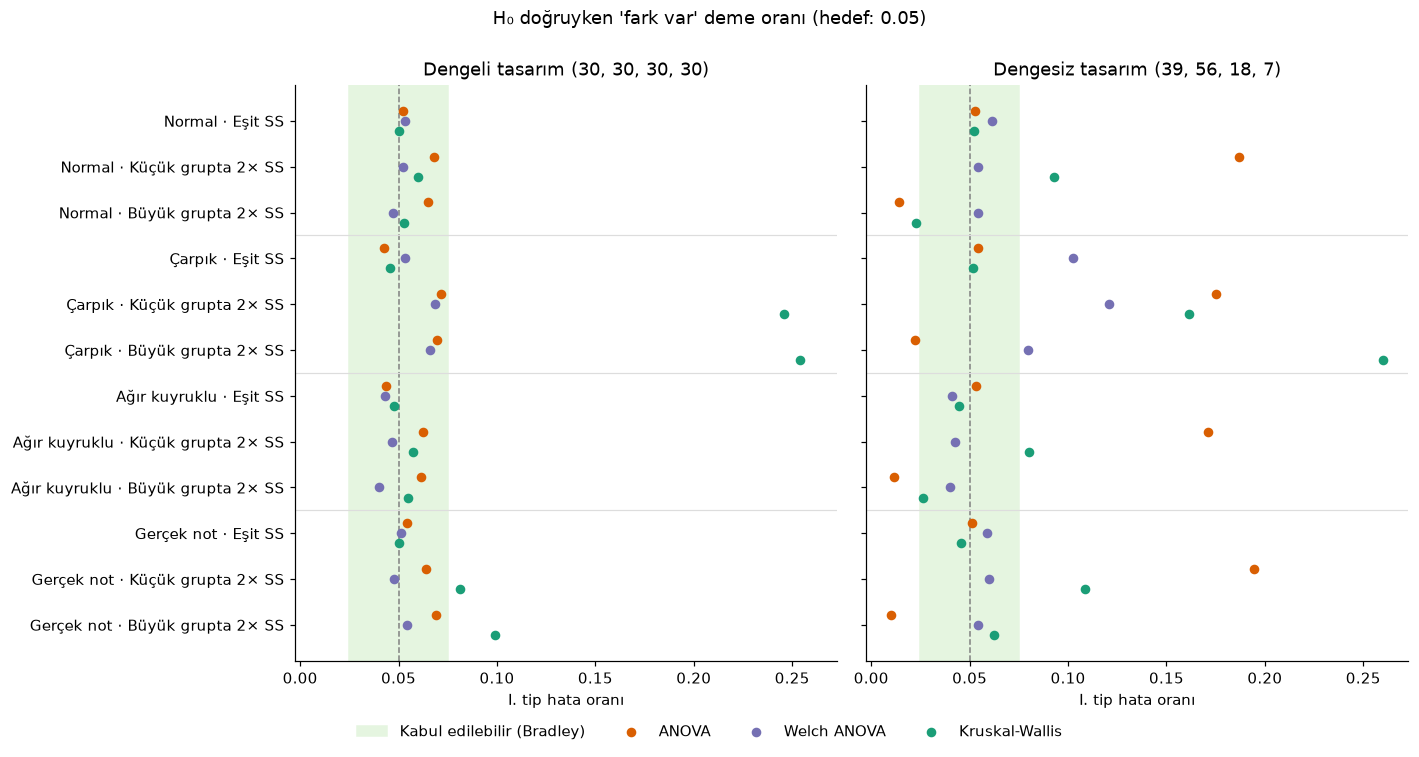

In [5]:
fig, eksenler = plt.subplots(1, 2, figsize=(13, 6.5), sharex=True)
for eksen, tasarim in zip(eksenler, TASARIMLAR):
    alt = tip1[tip1.Tasarım == tasarim].reset_index(drop=True)
    etiketler = [f"{r.Dağılım} · {r.Varyans}" for r in alt.itertuples()]
    eksen.axvspan(0.025, 0.075, color="#e5f5e0", label="Kabul edilebilir (Bradley)")
    eksen.axvline(ALPHA, color="gray", ls="--", lw=1)
    for k, test in enumerate(TESTLER):
        eksen.scatter(alt[test], np.arange(len(alt)) + (k - 1) * 0.22, color=TEST_RENK[test],
                      label=test, s=28, zorder=3)
    eksen.set_yticks(range(len(alt)), etiketler if tasarim == "Dengeli" else [""] * len(alt))
    eksen.invert_yaxis()
    eksen.set_title(f"{tasarim} tasarım {TASARIMLAR[tasarim]}")
    eksen.set_xlabel("I. tip hata oranı")
    for y in range(3, len(alt), 3):
        eksen.axhline(y - 0.5, color="#dddddd", lw=0.8)
fig.legend(*eksenler[1].get_legend_handles_labels(), loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.04), frameon=False)
plt.suptitle("H₀ doğruyken 'fark var' deme oranı (hedef: 0.05)", y=1.0)
plt.tight_layout()
plt.savefig(SEKIL / "simulasyon_tip1_hata.png", bbox_inches="tight")
plt.show()

In [6]:
uzun = tip1.melt(id_vars=["Dağılım", "Tasarım", "Varyans"], value_vars=list(TESTLER),
                 var_name="Test", value_name="Oran")
uzun["Kabul edilebilir"] = uzun.Oran.between(0.025, 0.075)
ozet = uzun.groupby("Test").agg(Ortalama=("Oran", "mean"), En_düşük=("Oran", "min"),
                                En_yüksek=("Oran", "max"),
                                Kabul_edilebilir_koşul=("Kabul edilebilir", "sum"))
ozet["Toplam koşul"] = len(tip1)
ozet.round(3)

,Ortalama,En_düşük,En_yüksek,Kabul_edilebilir_koşul,Toplam koşul
Test,,,,,
ANOVA,0.072,0.010,0.195,16,24
Kruskal-Wallis,0.088,0.023,0.260,14,24
Welch ANOVA,0.058,0.040,0.121,21,24


## 4. Güç analizi (H₁ doğru)

Etki örüntüsü gerçek veriden alınır: Portekizce dersinde gruplar arası standartlaştırılmış ortalama farkları. Bu örüntü bir `c` katsayısıyla ölçeklenir. `c = 1` gerçek verideki etkiye karşılık gelir. Varyanslar eşittir, toplam n = 120'dir.

In [7]:
grup_ort = por_g.groupby("studytime").G3.mean()
ortaklanmis_ss = np.sqrt(por_g.groupby("studytime").G3.var().mul(
    por_g.groupby("studytime").size() - 1).sum() / (len(por_g) - 4))
oruntu = ((grup_ort - grup_ort.iloc[0]) / ortaklanmis_ss).to_numpy()
print("Gerçek etki örüntüsü (SS cinsinden):", np.round(oruntu, 2))

katsayilar = np.linspace(0, 1.5, 7)
satirlar = []
for dagilim in DAGILIMLAR:
    for tasarim, n_ler in TASARIMLAR.items():
        for c in katsayilar:
            oranlar = simule_et(dagilim, n_ler, (1, 1, 1, 1), c * oruntu, tekrar=3000)
            satirlar.append({"Dağılım": dagilim, "Tasarım": tasarim, "c": c, **oranlar})
guc = pd.DataFrame(satirlar)

Gerçek etki örüntüsü (SS cinsinden): [0.   0.42 0.75 0.69]


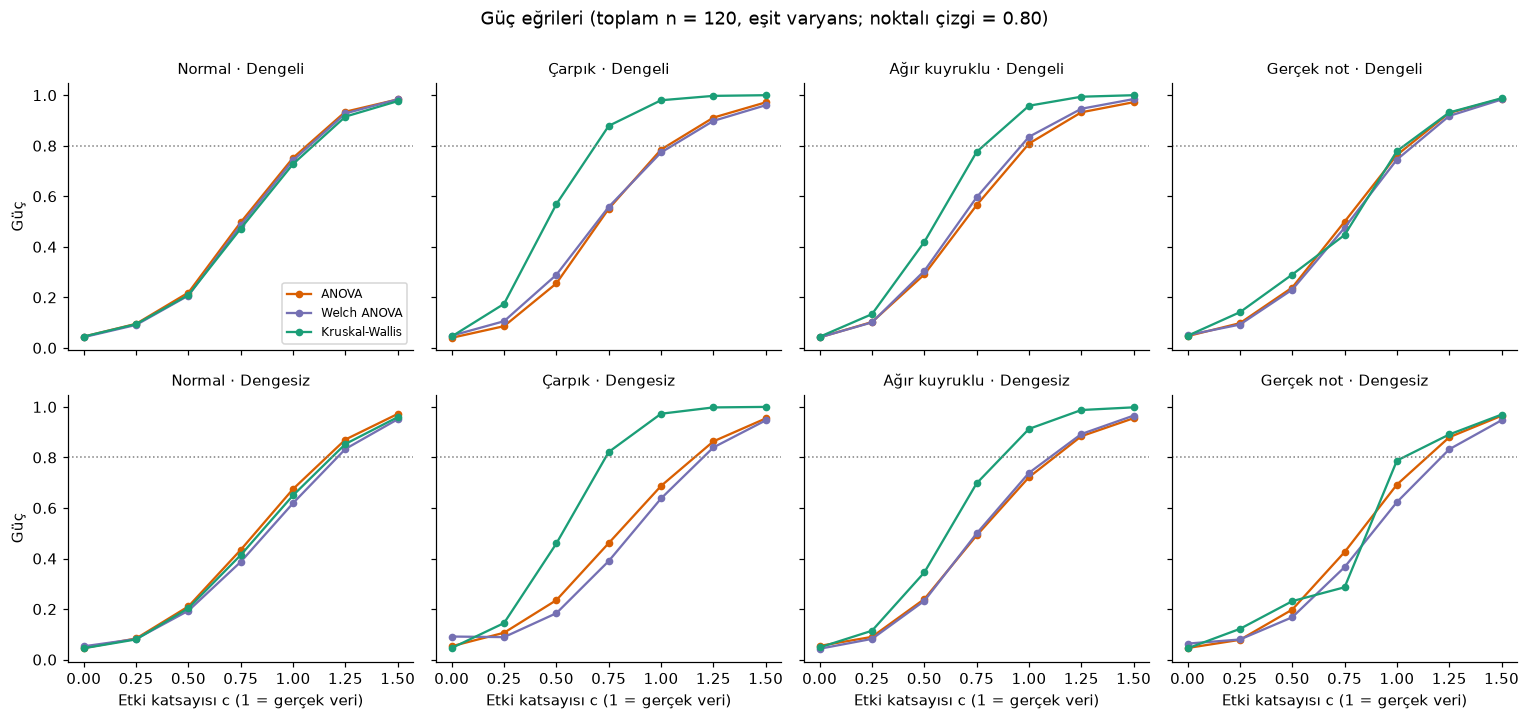

In [8]:
fig, eksenler = plt.subplots(2, 4, figsize=(14, 6.5), sharex=True, sharey=True)
for i, tasarim in enumerate(TASARIMLAR):
    for j, dagilim in enumerate(DAGILIMLAR):
        eksen = eksenler[i, j]
        alt = guc[(guc.Tasarım == tasarim) & (guc.Dağılım == dagilim)]
        for test in TESTLER:
            eksen.plot(alt.c, alt[test], marker="o", ms=4, color=TEST_RENK[test], label=test)
        eksen.axhline(0.8, color="gray", ls=":", lw=1)
        eksen.set_title(f"{dagilim} · {tasarim}", fontsize=10)
        if i == 1:
            eksen.set_xlabel("Etki katsayısı c (1 = gerçek veri)")
        if j == 0:
            eksen.set_ylabel("Güç")
eksenler[0, 0].legend(fontsize=8)
plt.suptitle("Güç eğrileri (toplam n = 120, eşit varyans; noktalı çizgi = 0.80)", y=1.0)
plt.tight_layout()
plt.savefig(SEKIL / "simulasyon_guc.png", bbox_inches="tight")
plt.show()

In [9]:
c1 = guc[np.isclose(guc.c, 1.0)].set_index(["Dağılım", "Tasarım"])[list(TESTLER)]
print("c = 1 (gerçek etki büyüklüğü) için güç:")
c1.round(3)

c = 1 (gerçek etki büyüklüğü) için güç:


ANOVA  Welch ANOVA  Kruskal-Wallis
Dağılım       Tasarım                                     
Normal        Dengeli   0.752        0.742           0.728
              Dengesiz  0.675        0.619           0.650
Çarpık        Dengeli   0.785        0.773           0.980
              Dengesiz  0.687        0.638           0.973
Ağır kuyruklu Dengeli   0.809        0.835           0.958
              Dengesiz  0.722        0.739           0.913
Gerçek not    Dengeli   0.763        0.745           0.779
              Dengesiz  0.693        0.623           0.788

## 5. Gerçek veri tasarımı için doğrudan yanıt

Son olarak simülasyon, `02_gercek_veri.ipynb` dosyasındaki **gerçek** koşullarla tekrarlanır: gerçek grup büyüklükleri (204, 298, 97, 35), gerçek grup standart sapmaları ve gerçek not dağılımı.

In [10]:
n_gercek = por_g.groupby("studytime").size().to_numpy()
ss_gercek = (por_g.groupby("studytime").G3.std() / por_g.G3.std()).to_numpy()
print("n:", n_gercek, "| göreli SS:", np.round(ss_gercek, 2))

gercek_tip1 = simule_et("Gerçek not", n_gercek, ss_gercek, (0, 0, 0, 0))
gercek_guc = {}
for c in (0.25, 0.5, 1.0):
    gercek_guc[c] = simule_et("Gerçek not", n_gercek, ss_gercek, c * oruntu)

sonuc = pd.DataFrame({"I. tip hata": gercek_tip1,
                      **{f"Güç (c = {c})": v for c, v in gercek_guc.items()}})
sonuc.round(3)

n: [204 298  97  35] | göreli SS: [0.91 1.   0.93 1.13]


,I. tip hata,Güç (c = 0.25),Güç (c = 0.5),Güç (c = 1.0)
ANOVA,0.067,0.304,0.867,1.0
Welch ANOVA,0.050,0.299,0.871,1.0
Kruskal-Wallis,0.102,0.449,0.931,1.0


## 6. Sonuç

**1. Klasik ANOVA dengesiz gruplarda tehlikelidir.** Gruplar dengeliyse ANOVA, dağılım ne olursa olsun I. tip hata oranını korur. Gruplar dengesiz **ve** küçük grubun varyansı büyükse, hata oranı %17–20'ye çıkar (yani hedefin yaklaşık 4 katı). Tersi durumda ANOVA aşırı tutucudur (%1); bu da gücü düşürür.

**2. Welch ANOVA en güvenilir testtir.** 24 koşulun 21'inde kabul edilebilir aralıkta kalır. Yalnızca çarpık dağılım ve dengesiz grupların birlikte görüldüğü koşullarda hata oranı biraz yükselir (%8–12). Normal dağılımda gücü ANOVA'ya çok yakındır.

**3. Kruskal-Wallis ortalama testi değildir.** Varyanslar eşitken hata oranını iyi korur ve çarpık veya ağır kuyruklu dağılımlarda en güçlü testtir (c = 1'de güç 0.91–0.98, ANOVA'da 0.69–0.81). Ancak varyanslar farklıysa "ortalamalar eşit" olduğu halde %25'e varan oranda anlamlı sonuç verir. Bunun nedeni şudur: Kruskal-Wallis "dağılımlar aynı mı?" sorusunu test eder. Çarpık bir dağılımın yayılımı değişince medyanı da kayar, test bu farkı yakalar. Yani yanılmaz, ama **farklı bir soruyu** yanıtlar.

**4. Gerçek veri için yanıt.** Portekizce verisinin koşullarında (n = 204/298/97/35, göreli SS 0.91–1.13, gerçek not dağılımı):

- Welch ANOVA: I. tip hata = 0.050 (ideal), ANOVA: 0.067, Kruskal-Wallis: 0.102.
- Gerçek etki büyüklüğünde (c = 1) üç testin gücü de ≈ 1'dir. Bu yüzden 02'deki Portekizce sonucu (p < .001) hangi test seçilirse seçilsin **sağlamdır**.
- Matematik dersindeki sınırda sonuçlar (p = .011 / .056) ise test seçimine duyarlıdır. Bu sonuçlar temkinle yorumlanmalıdır.

**5. Pratik öneri.** Ders kitaplarındaki "Shapiro-Wilk anlamlıysa Kruskal-Wallis kullan" kuralı büyük örneklemlerde yanıltıcıdır. Shapiro-Wilk, n büyüdükçe önemsiz sapmaları bile yakalar. Ortalamalar karşılaştırılmak isteniyorsa **varsayılan seçim Welch ANOVA olmalıdır**. Asıl soru "bir grubun değerleri sistematik olarak daha mı yüksek?" ise ve dağılım belirgin şekilde çarpıksa, Kruskal-Wallis daha güçlüdür.

*Simülasyon hatası:* 5000 tekrarda 0.05 oranının standart hatası ≈ 0.003'tür; güç tablolarında (3000 tekrar) ≈ 0.009'dur.
